# A5 · Recomendaciones cuantificadas
**Proyecto 01 — Retail Intelligence (RetailVenture C.A.)** · Tópicos Especiales para la Gestión de Datos · Prof. Armen Djenanian

El enunciado pide **cuantificar al menos tres recomendaciones** con la forma *"Si hacemos X, esperamos un incremento/reducción de Y % en Z métrica, equivalente a [monto]"*. Este notebook calcula esos montos a partir de `data/clean/` y de las tablas de A2–A4, para que cada cifra de la presentación sea reproducible.

**Convenciones**
- Horizonte: **6 meses**, igual que la proyección de fugas de A3. Como ventas, devoluciones y descuentos son estables en los 24 meses (A2 y A3), el valor semestral es el total de 24 meses ÷ 4.
- Métrica de referencia: **margen neto** (escenario base de A1: margen bruto − devuelto + costo recuperado).
- Cada recomendación lleva su **supuesto clave** y una **tabla de sensibilidad**, porque en la defensa se va a cuestionar justamente eso.

In [1]:
import pandas as pd, numpy as np
from pathlib import Path

pd.set_option('display.max_columns', 40); pd.set_option('display.width', 170)
CLEAN, TAB = Path('../data/clean'), Path('../outputs/tablas')
TAB.mkdir(parents=True, exist_ok=True)

ven = pd.read_csv(CLEAN / 'fact_ventas.csv', parse_dates=['fecha'])
cam = pd.read_csv(CLEAN / 'fact_campanas.csv', parse_dates=['fecha_envio'])

MESES = ven.fecha.dt.to_period('M').nunique()        # 24 meses de historia
A_6M = 6 / MESES                                       # factor para llevar 24 m -> 6 m
MN_6M = ven.margen_neto.sum() * A_6M                   # margen neto de referencia de un semestre
VENTAS_6M = ven.monto_neto.sum() * A_6M

pd.DataFrame({'métrica': ['Meses de historia', 'Ventas 6 m', 'Margen neto 6 m'],
              'valor': [MESES, round(VENTAS_6M), round(MN_6M)]})

,métrica,valor
0,Meses de historia,24
1,Ventas 6 m,4348247
2,Margen neto 6 m,780808


**Lectura:** la línea base de un semestre es de **≈ $4,35 M en ventas y ≈ $781K de margen neto**. Todos los impactos de abajo se expresan como porcentaje de ese margen.

## R1. Tope de descuento del 10 % en ventas

**Evidencia (A2):** los descuentos **no generan volumen** (efecto de +0,2 %, no significativo, con 4 pruebas distintas) y costaron $968K, el 22,5 % del margen bruto. Por encima del 20 %, Electrónica vende a pérdida. El canal online descuenta el doble que la tienda (7,5 % vs. 3,7 %).

**Cálculo:** para cada venta **no devuelta** se recupera la parte del descuento que excede el tope (`(descuento − tope) × ingreso bruto`). Las ventas devueltas se excluyen, porque al reembolsarse el monto el descuento no cambia el margen.

**Supuesto clave:** el volumen no cae al limitar el descuento. Como es el supuesto más débil, se calcula también **cuánto volumen podrían perder las ventas afectadas antes de que la medida deje de convenir** (punto de equilibrio).

In [2]:
nr = ven[ven.flag_devuelta == 0]
filas = []
for tope in [0.10, 0.15, 0.20]:
    afect = nr[nr.descuento > tope]
    ahorro = ((afect.descuento - tope) * afect.ingreso_bruto).sum()
    # Margen que dejarían de dar esas ventas si se perdieran: margen con el descuento ya topado
    margen_afect_topado = (afect.margen_bruto + (afect.descuento - tope) * afect.ingreso_bruto).sum()
    filas.append({'tope': f'{tope:.0%}',
                  'ventas_afectadas_%': len(ven[ven.descuento > tope]) / len(ven) * 100,
                  'margen_recuperado_6m': ahorro * A_6M,
                  'impacto_%_margen_neto': ahorro * A_6M / MN_6M * 100,
                  'pérdida_volumen_equilibrio_%': ahorro / margen_afect_topado * 100})
r1 = pd.DataFrame(filas)
r1.to_csv(TAB / 'a5_r1_tope_descuento.csv', index=False)
r1.round(1)

,tope,ventas_afectadas_%,margen_recuperado_6m,impacto_%_margen_neto,pérdida_volumen_equilibrio_%
0,10%,19.0,47619.1,6.1,32.8
1,15%,10.5,18190.1,2.3,31.0
2,20%,3.8,4060.0,0.5,31.6


**Lectura:** con un **tope del 10 %** (afecta al 19 % de las ventas) se recuperan **≈ $47,6K de margen por semestre, +6,1 % del margen neto**. La medida sigue conviniendo aunque esas ventas afectadas **perdieran hasta un 33 % de su volumen** (última columna): A2 no encontró ninguna respuesta del volumen al descuento, así que el riesgo es bajo. Un tope del 20 % solo elimina las ventas a pérdida y recupera mucho menos.

> **Si topamos el descuento en 10 %, esperamos un incremento de ~6 % en el margen neto, equivalente a ~$48K por semestre.**

## R2. Reducir las devoluciones por defecto en Electrónica y las de talla/defecto en Ropa

**Evidencia (A3):** las devoluciones se explican por la **categoría**, no por el cliente ni el canal: Ropa 21,8 % y Electrónica 17,7 % frente a ~10 % del resto. Aquí se baja un nivel más: ¿qué **motivo** cuesta más margen?

**Cálculo:** margen perdido por devolución = margen bruto − margen neto de la venta devuelta (es decir, lo reembolsado menos el costo recuperado). Si el motivo es *defectuoso* o *fraude*, el producto no se recupera (supuesto de A1), por eso esos motivos cuestan mucho más.

In [3]:
dev = ven[ven.flag_devuelta == 1].copy()
dev['margen_perdido'] = dev.margen_bruto - dev.margen_neto
por_motivo = (dev.groupby(['categoria', 'motivo_devolucion'])
                 .agg(devoluciones=('transaccion_id', 'size'), margen_perdido_24m=('margen_perdido', 'sum'))
                 .reset_index().sort_values('margen_perdido_24m', ascending=False))
por_motivo['%_del_total'] = por_motivo.margen_perdido_24m / dev.margen_perdido.sum() * 100
por_motivo.to_csv(TAB / 'a5_r2_devoluciones_motivo.csv', index=False)
por_motivo.head(8).round(1)

,categoria,motivo_devolucion,devoluciones,margen_perdido_24m,%_del_total
23,Electrónica,Producto_defectuoso,408,392017.8,33.0
29,Hogar_y_Deco,Producto_defectuoso,232,114766.0,9.7
35,Ropa_y_Calzado,Producto_defectuoso,512,86603.3,7.3
17,Deportes,Producto_defectuoso,262,74603.0,6.3
22,Electrónica,No_cumple_expectativas,578,74516.6,6.3
28,Hogar_y_Deco,No_cumple_expectativas,329,53682.8,4.5
21,Electrónica,Fraude_reportado,58,42038.1,3.5
16,Deportes,No_cumple_expectativas,323,34679.9,2.9


**Lectura: una sola combinación explica un tercio de todo el margen perdido por devoluciones.** *Electrónica × producto defectuoso* cuesta **$392K en 24 meses (33 % del total)**, porque cada unidad defectuosa se reembolsa completa y no vuelve al inventario. En Ropa, los motivos accionables son *defectuoso* ($87K) y *talla incorrecta* ($23K, exclusivo de Ropa).

La acción propuesta es **control de calidad con los proveedores de Electrónica** (auditar los productos con más defectos, exigir garantía o reposición al proveedor) y **guía de tallas + control de calidad en Ropa**. No hay un dato externo que diga cuánto bajan las devoluciones con estas medidas, así que se presenta como **escenario** con sensibilidad.

In [4]:
objetivo = (((dev.categoria == 'Electrónica') & (dev.motivo_devolucion == 'Producto_defectuoso')) |
            ((dev.categoria == 'Ropa_y_Calzado') & dev.motivo_devolucion.isin(['Producto_defectuoso', 'Talla_incorrecta'])))
base_6m = dev.loc[objetivo, 'margen_perdido'].sum() * A_6M
r2 = pd.DataFrame({'reducción_de_esas_devoluciones': ['15 %', '30 % (escenario central)', '50 %']})
r2['margen_recuperado_6m'] = [base_6m * x for x in (0.15, 0.30, 0.50)]
r2['impacto_%_margen_neto'] = r2.margen_recuperado_6m / MN_6M * 100
r2.to_csv(TAB / 'a5_r2_escenarios.csv', index=False)
pd.concat([pd.DataFrame({'reducción_de_esas_devoluciones': ['Margen perdido hoy (6 m)'],
                         'margen_recuperado_6m': [base_6m], 'impacto_%_margen_neto': [base_6m / MN_6M * 100]}), r2]).round(1)

,reducción_de_esas_devoluciones,margen_recuperado_6m,impacto_%_margen_neto
0,Margen perdido hoy (6 m),125497.7,16.1
0,15 %,18824.7,2.4
1,30 % (escenario central),37649.3,4.8
2,50 %,62748.9,8.0


**Lectura:** esas tres combinaciones hacen perder **≈ $125K de margen por semestre (16 % del margen neto)**. Reducirlas un 30 % recupera **≈ $37,5K por semestre (+4,8 % del margen neto)**.

> **Si reducimos un 30 % las devoluciones por defecto en Electrónica y por defecto/talla en Ropa, esperamos un incremento de ~5 % en el margen neto, equivalente a ~$37K por semestre.**

## R3. Campañas: tope de descuento del 10 % y sacar a los Inactivos del envío masivo

**Evidencia (A4):** el descuento de campaña sube la conversión (+1,3 pp por cada +5 pp), pero el **53 % de los convertidos habría comprado sin descuento**, así que el ROI incremental es **negativo (−0,16x)**. El descuento solo crea margen hasta el **10 %**. Además, **Inactivo** recibe el 14 % de los envíos y es el que menos convierte, por baja intención (61 % sin compras previas), no por quejas ni devoluciones.

**Cálculo:** se reutiliza el escenario de A4 (`a4_escenario_tope_descuento.csv`), que ya descuenta las conversiones que se perderían al bajar el descuento. Se agrega el peso de Inactivo en envíos y en costo de descuento.

In [5]:
esc = pd.read_csv(TAB / 'a4_escenario_tope_descuento.csv', index_col=0)
ina = cam[cam.segmento == 'Inactivo']
r3 = pd.DataFrame({
    'concepto': ['Margen de campañas hoy (6 m)', 'Margen de campañas con tope 10 % (6 m)', 'Variación del margen de campañas',
                 'Costo de descuento evitado (6 m)', 'Conversiones perdidas (6 m)',
                 '% de envíos a Inactivo', 'Conversión de Inactivo', 'Conversión del resto'],
    'valor': [esc.loc['margen de campañas (24 m)', 'Actual'] * A_6M,
              esc.loc['margen de campañas (24 m)', 'Tope 10%'] * A_6M,
              esc.loc['margen de campañas (24 m)', 'variación_%'] * 100,
              -esc.loc['costo del descuento (24 m)', 'diferencia_6m'],
              -esc.loc['conversiones (24 m)', 'diferencia_6m'],
              len(ina) / len(cam) * 100,
              ina.convertido.mean() * 100,
              cam[cam.segmento != 'Inactivo'].convertido.mean() * 100]})
r3.to_csv(TAB / 'a5_r3_campanas.csv', index=False)
r3.round(1)

,concepto,valor
0,Margen de campañas hoy (6 m),8457.7
1,Margen de campañas con tope 10 % (6 m),11292.1
2,Variación del margen de campañas,33.5
3,Costo de descuento evitado (6 m),5432.8
4,Conversiones perdidas (6 m),24.5
5,% de envíos a Inactivo,14.0
6,Conversión de Inactivo,5.5
7,Conversión del resto,9.6


**Lectura:** con el tope del 10 % el **margen de campañas sube un 34 % (+$2,8K por semestre)** y se dejan de regalar ≈ $5,4K en descuentos, a cambio de unas 24 conversiones menos que en su mayoría habrían comprado igual. En monto es la recomendación más pequeña, porque las campañas mueven poco dinero, pero es la que mejor corrige el problema que la gerencia sí había detectado. Los envíos a Inactivo (5,5 % de conversión) se pueden reasignar a Premium, que convierte 13,7 %, 2,5 veces más.

> **Si topamos el descuento de campaña en 10 % y dejamos de enviar campañas masivas a Inactivos, esperamos un incremento de 34 % en el margen de campañas, equivalente a ~$2,8K por semestre (y ~$5,4K menos de descuento cedido).**

## Consolidado de las recomendaciones

In [6]:
cons = pd.DataFrame({
    'recomendación': ['R1 · Tope de descuento 10 % en ventas',
                      'R2 · Calidad en Electrónica y tallas en Ropa (−30 % devoluciones objetivo)',
                      'R3 · Campañas: tope 10 % y excluir Inactivos'],
    'métrica': ['Margen neto', 'Margen neto', 'Margen de campañas'],
    'margen_6m': [r1.loc[0, 'margen_recuperado_6m'], r2.loc[1, 'margen_recuperado_6m'],
                  esc.loc['margen de campañas (24 m)', 'diferencia_6m']],
    'supuesto_clave': ['El volumen no cae (A2: efecto del descuento no significativo)',
                       'Escenario: la reducción del 30 % no viene de un dato externo',
                       'Modelo de A4: el descuento es asignado como al azar'],
    'dificultad': ['Baja (política comercial)', 'Media (proveedores y contenido web)', 'Baja (segmentación de envíos)']})
cons['%_margen_neto_6m'] = cons.margen_6m / MN_6M * 100
total = cons.margen_6m.sum()
cons.to_csv(TAB / 'a5_recomendaciones_consolidado.csv', index=False)
display(cons.round(1))
pd.DataFrame({'total_6m': [round(total)], '%_margen_neto_6m': [round(total / MN_6M * 100, 1)]})

,recomendación,métrica,margen_6m,supuesto_clave,dificultad,%_margen_neto_6m
0,R1 · Tope de descuento 10 % en ventas,Margen neto,47619.1,El volumen no cae (A2: efecto del descuento no...,Baja (política comercial),6.1
1,R2 · Calidad en Electrónica y tallas en Ropa (...,Margen neto,37649.3,Escenario: la reducción del 30 % no viene de u...,Media (proveedores y contenido web),4.8
2,R3 · Campañas: tope 10 % y excluir Inactivos,Margen de campañas,2834.4,Modelo de A4: el descuento es asignado como al...,Baja (segmentación de envíos),0.4


,total_6m,%_margen_neto_6m
0,88103,11.3


**Lectura:** las tres recomendaciones juntas recuperan **≈ $88K de margen por semestre, +11 % del margen neto**. El orden de prioridad para la presentación sale de comparar impacto y dificultad: **R1 primero** (mayor monto y solo requiere cambiar una política), **R2 segundo** (la fuga más grande, pero requiere trabajo con proveedores) y **R3 tercero** (monto pequeño, pero corrige el síntoma de marketing que motivó el encargo).

Los montos no se solapan: R1 actúa sobre ventas **no devueltas**, R2 sobre ventas **devueltas** y R3 sobre el descuento de **campañas**, que A4 mide aparte. Para una política nueva se recomienda confirmar el efecto con una prueba A/B antes de aplicarla a toda la cadena.

## Figuras para la presentación ejecutiva
Tres visualizaciones nuevas que completan el relato de A5 (las demás se reutilizan de A2–A4). Se guardan en `outputs/figuras/` con prefijo `a5_` y con el mismo estilo que el resto.

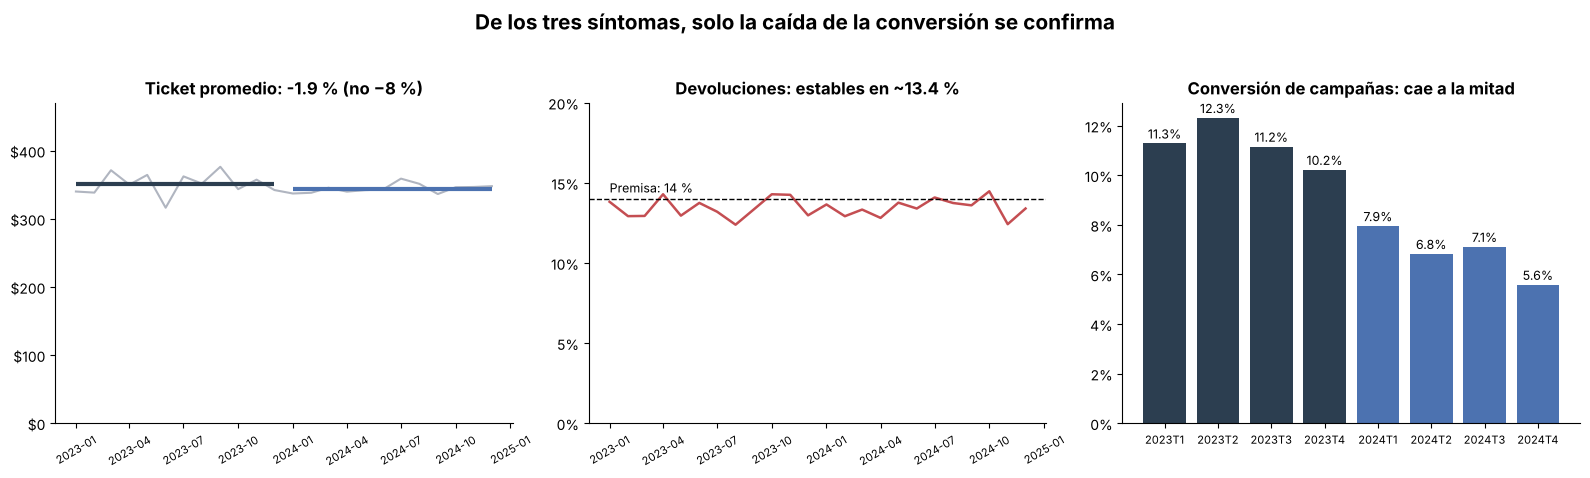

In [7]:
import matplotlib.pyplot as plt, matplotlib.ticker as mtick
FIG = Path('../outputs/figuras'); FIG.mkdir(parents=True, exist_ok=True)
plt.rcParams.update({'axes.spines.top': False, 'axes.spines.right': False, 'axes.titleweight': 'bold',
                     'axes.titlesize': 12, 'text.parse_math': False})
AZUL, NAVY, GRIS, ROJO, VERDE = '#4C72B0', '#2C3E50', '#B0B5C0', '#C44E52', '#55A868'

# V1 · Los tres síntomas de la gerencia, medidos en el tiempo
mes = ven.assign(mes=ven.fecha.dt.to_period('M')).groupby('mes').agg(ticket=('monto_neto', 'mean'), dev=('flag_devuelta', 'mean'))
mes.index = mes.index.to_timestamp()
conv = cam.assign(t=cam.fecha_envio.dt.to_period('Q')).groupby('t').convertido.mean()
anual_t = ven.groupby(ven.fecha.dt.year).monto_neto.mean()
var_ticket = (anual_t[2024] / anual_t[2023] - 1) * 100

fig, ax = plt.subplots(1, 3, figsize=(16, 4.6))
ax[0].plot(mes.index, mes.ticket, color=GRIS, lw=1.5)
for a, c in [(2023, NAVY), (2024, AZUL)]:
    ax[0].hlines(anual_t[a], pd.Timestamp(f'{a}-01-01'), pd.Timestamp(f'{a}-12-01'), color=c, lw=3)
ax[0].set_ylim(0, mes.ticket.max() * 1.25); ax[0].yaxis.set_major_formatter(mtick.StrMethodFormatter('${x:,.0f}'))
ax[0].set_title(f'Ticket promedio: {var_ticket:+.1f} % (no −8 %)')
ax[1].plot(mes.index, mes.dev * 100, color=ROJO, lw=1.8)
ax[1].axhline(14, color='black', ls='--', lw=1); ax[1].text(mes.index[0], 14.4, 'Premisa: 14 %', fontsize=9)
ax[1].set_ylim(0, 20); ax[1].yaxis.set_major_locator(mtick.MultipleLocator(5)); ax[1].yaxis.set_major_formatter(mtick.PercentFormatter(decimals=0))
ax[1].set_title(f'Devoluciones: estables en ~{ven.flag_devuelta.mean()*100:.1f} %')
lbl = [str(q).replace('Q', 'T') for q in conv.index]
ax[2].bar(lbl, conv.values * 100, color=[NAVY] * 4 + [AZUL] * 4)
for i, v in enumerate(conv.values * 100): ax[2].text(i, v + 0.2, f'{v:.1f}%', ha='center', fontsize=9)
ax[2].yaxis.set_major_formatter(mtick.PercentFormatter(decimals=0)); ax[2].tick_params(axis='x', labelsize=8)
ax[2].set_title('Conversión de campañas: cae a la mitad')
for a in ax[:2]: a.tick_params(axis='x', labelsize=8, rotation=30)
fig.suptitle('De los tres síntomas, solo la caída de la conversión se confirma', fontsize=15, fontweight='bold', y=1.03)
fig.tight_layout(); fig.savefig(FIG / 'a5_sintomas.png', dpi=150, bbox_inches='tight'); plt.show()

**Lectura:** el ticket baja apenas un **1,9 %** y las devoluciones se mantienen en **~13,4 %** durante los 24 meses, sin subir en el último trimestre. La conversión sí cae a la mitad (11,3 % → 5,6 % del primer al último trimestre). Por eso el relato no parte de las premisas del caso, sino de lo que los datos confirman.

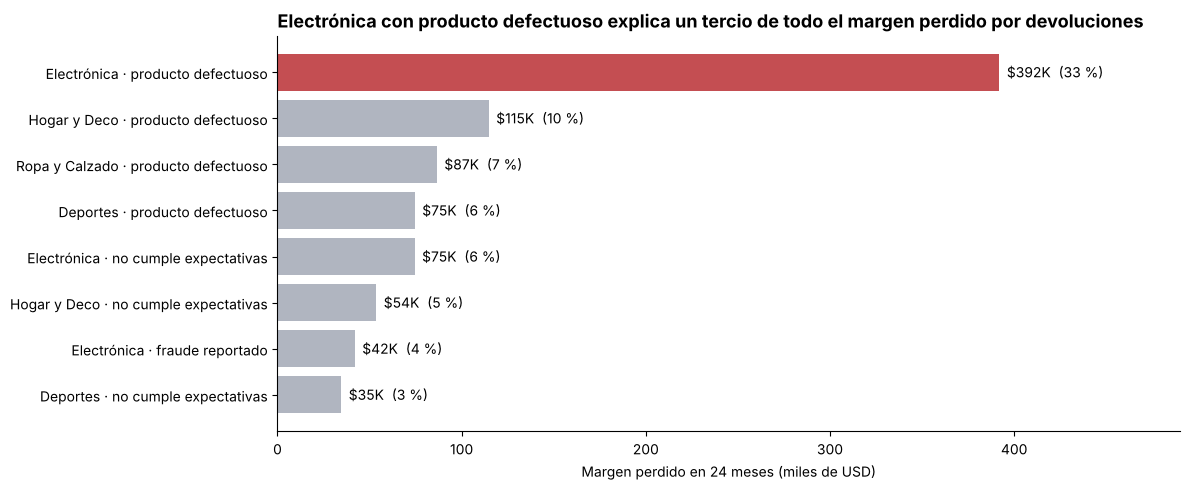

In [8]:
# V5 · Qué motivo de devolución cuesta más margen
top = por_motivo.head(8).iloc[::-1].copy()
top['etq'] = top.categoria.str.replace('_', ' ') + ' · ' + top.motivo_devolucion.str.replace('_', ' ').str.lower()
col = [ROJO if (c == 'Electrónica' and m == 'Producto_defectuoso') else GRIS for c, m in zip(top.categoria, top.motivo_devolucion)]
fig, ax = plt.subplots(figsize=(12, 5))
ax.barh(top.etq, top.margen_perdido_24m / 1000, color=col)
for i, (v, pc) in enumerate(zip(top.margen_perdido_24m / 1000, top['%_del_total'])):
    ax.text(v + 4, i, f'${v:,.0f}K  ({pc:.0f} %)', va='center', fontsize=10)
ax.set_xlabel('Margen perdido en 24 meses (miles de USD)'); ax.set_xlim(0, top.margen_perdido_24m.max() / 1000 * 1.25)
ax.set_title('Electrónica con producto defectuoso explica un tercio de todo el margen perdido por devoluciones',
             fontsize=13, loc='left')
fig.tight_layout(); fig.savefig(FIG / 'a5_devoluciones_motivo.png', dpi=150, bbox_inches='tight'); plt.show()

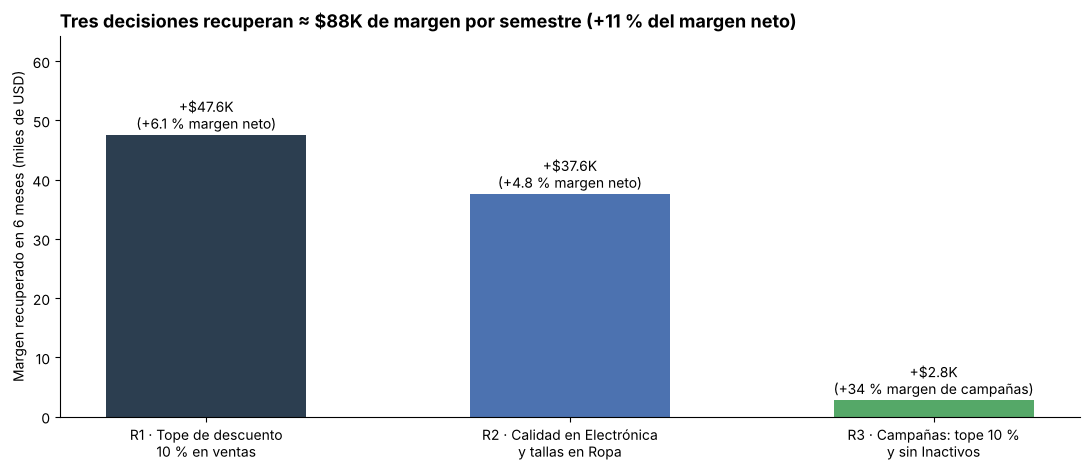

In [9]:
# V9 · Impacto de las recomendaciones
etq = ['R1 · Tope de descuento\n10 % en ventas', 'R2 · Calidad en Electrónica\ny tallas en Ropa', 'R3 · Campañas: tope 10 %\ny sin Inactivos']
fig, ax = plt.subplots(figsize=(11, 4.8))
b = ax.bar(etq, cons.margen_6m / 1000, color=[NAVY, AZUL, VERDE], width=0.55)
txt = [f'+${v/1000:,.1f}K\n(+{p:.1f} % margen neto)' for v, p in zip(cons.margen_6m, cons['%_margen_neto_6m'])]
txt[2] = f'+${cons.margen_6m[2]/1000:,.1f}K\n(+34 % margen de campañas)'
for r, t in zip(b, txt): ax.text(r.get_x() + r.get_width() / 2, r.get_height() + 1, t, ha='center', fontsize=10)
ax.set_ylabel('Margen recuperado en 6 meses (miles de USD)'); ax.set_ylim(0, cons.margen_6m.max() / 1000 * 1.35)
ax.set_title(f'Tres decisiones recuperan ≈ ${total/1000:,.0f}K de margen por semestre (+{total/MN_6M*100:.0f} % del margen neto)',
             fontsize=13, loc='left')
fig.tight_layout(); fig.savefig(FIG / 'a5_impacto_recomendaciones.png', dpi=150, bbox_inches='tight'); plt.show()